# CMMD Training Framework

In [3]:
# @@ENV@@ — Keras backend, visible GPU and global seed
import os

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)


import kagglesdk.kaggle_env as kaggle_env

if not hasattr(kaggle_env, "get_web_endpoint"):
    kaggle_env.get_web_endpoint = kaggle_env.get_endpoint

import kagglehub
import keras
import keras_cv

print("GPUs:", gpus)

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Setup

In [4]:
# @@CFG@@ — every knob of the training run in one place
class CFG:
    verbose = 2  # Verbosity
    seed = 59  # Random seed
    neg_sample = 1 # Downsample negative train set class
    pos_sample = 1  # Upsample positive train set class
    val_neg_sample = 1
    val_pos_sample = 1 
    preset = "efficientnetv2_b2_imagenet"  # Name of pretrained classifier
    image_size = (256, 256)  # Input image size
    epochs = 20 # Training epochs
    batch_size = 64  # Batch size
    shuffle_buffer = 1024
    lr_mode = "cos" # LR scheduler mode from one of "cos", "step", "exp"
    class_names = ['target']
    num_classes = 1
    seeds = [8, 47, 53, 71, 90, 101]
    opt = keras.optimizers.Adam() # LR scheduler owns the rate, set from epoch 0
    loss = keras.losses.BinaryCrossentropy(label_smoothing=0.02)

keras.utils.set_random_seed(CFG.seed)

I0000 00:00:1792792019.012793 3037045 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22800 MB memory:  -> device: 0, name: Quadro RTX 6000, pci bus id: 0000:17:00.0, compute capability: 7.5


In [5]:
# @@PATHS@@ — dataset, variant and row identity are declared HERE; every path derives from them
import sys

BASE_PATH = os.environ.get("DUM_BASE", os.environ.get("ISIC24_BASE", "/mnt/disk1/home/cgiovannoni/mod-attendance"))
sys.path.insert(0, os.path.join(BASE_PATH, "src")) if os.path.join(BASE_PATH, "src") not in sys.path else None

from isic24 import paths as pth
from isic24 import xai_subset as xs

pth.DATASET, pth.VARIANT = "cmmd", "processed" 
xs.ID_COL = "image_id"                             # row identity column of this dataset

DATA_DIR = str(pth.data_dir())                    # images (hdf5) live at dataset level
DATA_PATH = str(pth.data_path())                  # metadata of this variant
ART_PATH = str(pth.art_path())
FEATURE_SPACE_PATH = os.path.join(ART_PATH, "feature_space")
RUNS_PATH = os.path.join(ART_PATH, "runs")
SUMMARIES_PATH = os.path.join(ART_PATH, "summaries")

TRAIN_META = os.path.join(DATA_PATH, "train-metadata.parquet")
TEST_META = os.path.join(DATA_PATH, "test-metadata.parquet")
TRAIN_HDF5 = os.path.join(DATA_DIR, "train-image.hdf5")
TEST_HDF5 = os.path.join(DATA_DIR, "test-image.hdf5")

print(f"dataset={pth.DATASET}/{pth.VARIANT} | id={xs.ID_COL}\n  data {DATA_PATH}\n  art  {ART_PATH}")

dataset=cmmd/processed | id=image_id
  data /mnt/disk1/home/cgiovannoni/mod-attendance/data/cmmd/processed
  art  /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed


In [6]:
 # @@CUSTOM_LAYERS@@ — register shared Keras layers before loading checkpoints
_SRC = os.path.join(BASE_PATH, "src")
if _SRC not in sys.path:
    sys.path.insert(0, _SRC)

from isic24.mod_attendance import (
    ConstantScale, ScalarMultiply, LearnableAlpha, FusionWithGamma, GateEntropyLoss,
    assert_loss_is_per_sample,
)

In [7]:
# @@DATA@@ — load the parquet
import pandas as pd

# Train + Valid
df = pd.read_parquet(TRAIN_META)

# Testing
testing_df = pd.read_parquet(TEST_META)

print(df['target'].value_counts())
print(testing_df['target'].value_counts())

target
1    2100
0     886
Name: count, dtype: int64
target
1    526
0    222
Name: count, dtype: int64


In [8]:
# @@SPLIT@@ — StratifiedGroupKFold grouped by patient_id; fold VAL_FOLD is validation
from sklearn.model_selection import StratifiedGroupKFold

N_SPLITS, VAL_FOLD = 5, 0

df = df.reset_index(drop=True) # ensure continuous index
df["fold"] = -1
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=CFG.seed)
for i, (training_idx, validation_idx) in enumerate(sgkf.split(df, y=df.target, groups=df.patient_id)):
    df.loc[validation_idx, "fold"] = int(i)

training_df = df.query("fold != @VAL_FOLD").copy()
validation_df = df.query("fold == @VAL_FOLD").copy()
print(f"# Num Train: {len(training_df)} | Num Valid: {len(validation_df)}")

# Num Train: 2390 | Num Valid: 596


In [9]:
# @@FEAT_COLS@@ — define pre-diagnostic clinical features available independently of image grading

NUM_COLS = ["age"]
CAT_COLS = [
    "view",
    "laterality",
]
FEAT_COLS = [*CAT_COLS, *NUM_COLS]

for name, frame in (("training source", df), ("testing", testing_df)):
    missing = [c for c in FEAT_COLS if c not in frame.columns]
    assert not missing, f"{name} is missing model features: {missing}"

    non_numeric = [
        c for c in NUM_COLS
        if not pd.api.types.is_numeric_dtype(frame[c])
    ]
    assert not non_numeric, f"{name} has non-numeric model features: {non_numeric}"

print(
    f"[features] {len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical "
    f"= {len(FEAT_COLS)} raw features"
)

[features] 1 numeric + 2 categorical = 3 raw features


In [10]:
# @@IMPUTE@@ — fit numeric medians on training only and represent missing categories explicitly
MEDIANS = training_df[NUM_COLS].median()

all_nan = MEDIANS.index[MEDIANS.isna()].tolist()
assert not all_nan, f"all-NaN training features cannot be imputed: {all_nan}"


def impute(frame, name):
    frame = frame.copy()
    holes = frame[FEAT_COLS].isna().mean()
    holes = holes[holes > 0].sort_values(ascending=False)

    frame[NUM_COLS] = frame[NUM_COLS].fillna(MEDIANS).astype("float32")
    frame[CAT_COLS] = frame[CAT_COLS].fillna("unknown").astype(str)

    left = frame[FEAT_COLS].isna().sum()
    left = left[left > 0]
    assert left.empty, f"[{name}] NaN left in model features:\n{left.to_string()}"

    for col, fraction in holes.items():
        fill = f"{MEDIANS[col]:.4g}" if col in NUM_COLS else "unknown"
        print(f"    {col:32s} {fraction:7.2%}  ->  {fill}")

    print(f"[{name}] imputed {len(holes)} of {len(FEAT_COLS)} model features")
    return frame


training_df = impute(training_df, "training")
validation_df = impute(validation_df, "validation")
testing_model_df = impute(testing_df, "testing")
training_natural_df = training_df.copy()

[training] imputed 0 of 3 model features
[validation] imputed 0 of 3 model features
[testing] imputed 0 of 3 model features


In [11]:
# @@RESAMPLE@@ — training: downsample negatives, upsample positives; validation: negatives only
print("Training distribution before sampling (%):")
print(training_df.target.value_counts(normalize=True) * 100)

majority_df = training_df.query("target == 0").sample(frac=CFG.neg_sample,
                                                      random_state=CFG.seed,
                                                      )

minority_df = training_df.query("target == 1").sample(frac=CFG.pos_sample,
                                                      replace=True,
                                                      random_state=CFG.seed,
                                                      )

training_df = (pd.concat([majority_df, minority_df], axis=0).sample(frac=1.0,
                                                                    random_state=CFG.seed
                                                                    ).reset_index(drop=True))

_val_rows = len(validation_df)
validation_df = pd.concat([validation_df.query("target == 0").sample(frac=CFG.val_neg_sample, 
                                                                     random_state=CFG.seed),
                           validation_df.query("target == 1").sample(
                               frac=CFG.val_pos_sample,
                               random_state=CFG.seed,
                           ),], 
                           axis=0).sort_index().reset_index(drop=True)

assert not validation_df[xs.ID_COL].duplicated().any(), "validation holds duplicated rows"

print("\nTraining distribution after sampling (%):")
print(training_df.target.value_counts(normalize=True) * 100)
print(f"\nValidation: {_val_rows} -> {len(validation_df)} rows | "
      f"{int(validation_df.target.sum())} positives kept | "
      f"prevalence {validation_df.target.mean():.4f}")

Training distribution before sampling (%):
target
1    70.292887
0    29.707113
Name: proportion, dtype: float64

Training distribution after sampling (%):
target
1    70.292887
0    29.707113
Name: proportion, dtype: float64

Validation: 596 -> 596 rows | 420 positives kept | prevalence 0.7047


In [12]:
# @@CLASS_WEIGHTS@@ —
# if resampling is enable, the weights will be computed on the ALREADY resampled frame: positives are upsampled 5x and then weighted ~2x again
# That double compensation shifts Brier/ECE; choose either one (resampling or class weights).

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

USE_CLASS_WEIGHT = False
class_weights = None

if USE_CLASS_WEIGHT:
    weights = compute_class_weight("balanced", classes=np.unique(training_df.target), y=training_df.target)
    class_weights = dict(enumerate(weights))

print("Class weights:", class_weights, "| enabled:", USE_CLASS_WEIGHT)

Class weights: None | enabled: False


In [13]:
# @@HDF5@@ — open the image stores
import h5py

training_validation_hdf5 = h5py.File(TRAIN_HDF5, 'r')
testing_hdf5 = h5py.File(TEST_HDF5, 'r')

In [14]:
# @@VAL_SNAPSHOT@@ — freeze the validation identity once; every later run verifies against it
import json as _json

os.makedirs(ART_PATH, exist_ok=True)

_val_snap = os.path.join(ART_PATH, "validation_snapshot.json")
_live_ids = [str(v) for v in xs.row_ids(validation_df)]

if os.path.exists(_val_snap):
    _snap = _json.load(open(_val_snap))
    _frozen = [str(v) for v in _snap.get("row_ids", _snap.get("isic_ids_sorted", []))]
    if _live_ids != _frozen:
        _lost, _new = set(_frozen) - set(_live_ids), set(_live_ids) - set(_frozen)
        _what = ("the same rows in a DIFFERENT ORDER" if not (_lost or _new)
                 else f"a different population: {len(_lost)} missing, {len(_new)} new")
        raise RuntimeError(
            f"[VAL SNAPSHOT] the live validation ({len(_live_ids)} rows) is not the frozen one "
            f"({len(_frozen)} rows) — {_what}.\n"
            f"  Every checkpoint is held out from the frozen rows and every val_index in the XAI "
            f"artifacts is a position into them, so both membership and order are load-bearing.\n"
            f"  If the split changed on purpose: delete {_val_snap}, re-run this cell, and treat "
            f"the runs already on disk as historical.")
    _state = "verified"
else:
    _json.dump({"n": len(_live_ids), "row_id_col": xs.ID_COL, "seed": int(CFG.seed),
                "n_splits": int(N_SPLITS), "val_fold": int(VAL_FOLD),
                "val_neg_sample": float(CFG.val_neg_sample),
                "val_pos_sample": float(CFG.val_pos_sample),
                "prevalence": round(float(validation_df.target.mean()), 6),
                "row_ids": _live_ids}, open(_val_snap, "w"), indent=1)
    _state = "frozen"

print(f"[VAL SNAPSHOT] {_state} — {len(_live_ids)} rows, "
      f"{int(validation_df.target.sum())} positive -> {_val_snap}")


# The frames this run trains and evaluates on, frozen next to their identity: the post-hoc
# loads them instead of rebuilding the split, so no second code path can diverge from this one.
for _name, _frame in (("evaluation", validation_df), ("training", training_df)):
    _fpath = os.path.join(ART_PATH, f"{_name}_frame.parquet")
    _rows = [str(v) for v in xs.row_ids(_frame)]
    if not os.path.exists(_fpath):
        _frame.to_parquet(_fpath, index=False)
        print(f"[FRAME] {_name} frozen — {len(_rows)} rows -> {_fpath}")
    else:
        _disk = [str(v) for v in pd.read_parquet(_fpath, columns=[xs.ID_COL])[xs.ID_COL]]
        if _disk != _rows:
            raise RuntimeError(
                f"[FRAME] {_fpath} holds {len(_disk)} rows against the live {_name} frame's "
                f"{len(_rows)}, or the same rows in a different order. Every val_index in the XAI "
                f"artifacts is a position into the frozen frame: if the split changed on purpose, "
                f"delete it together with validation_snapshot.json.")
        print(f"[FRAME] {_name} verified — {len(_rows)} rows == {_fpath}")

[VAL SNAPSHOT] verified — 596 rows, 420 positive -> /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/validation_snapshot.json
[FRAME] evaluation verified — 596 rows == /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/evaluation_frame.parquet
[FRAME] training verified — 2390 rows == /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/training_frame.parquet


In [15]:
# @@CLASS_DISTRIBUTION@@ — report resampled training and untouched validation targets
print("training:", training_df.target.value_counts(),
      "\nvalidation:", validation_df.target.value_counts(), sep="\n")

training:
target
1    1680
0     710
Name: count, dtype: int64

validation:
target
1    420
0    176
Name: count, dtype: int64


In [16]:
# @@DATASET_BUILDERS@@ — decode every CXR as RGB and build deterministic cached datasets
from tqdm import tqdm

def build_augmenter(seed):
    augmenter = keras_cv.layers.Augmenter([
        keras_cv.layers.RandomApply(
            keras_cv.layers.RandomCutout(
                height_factor=(0.02, 0.06),
                width_factor=(0.02, 0.06),
                seed=seed,
            ),
            rate=0.5,
            seed=seed + 1,
        ),
        keras_cv.layers.RandomFlip(
            mode="horizontal",
            rate=0.5,
            seed=seed + 2,
        ),
    ])

    def augment(inp, label):
        images = augmenter({"images": inp["images"]})["images"]
        return {"images": images, "features": inp["features"]}, label

    return augment


def build_decoder(with_labels=True, target_size=CFG.image_size):
    def decode_image(inp):
        image = tf.io.decode_jpeg(inp["images"], channels=3)
        image = tf.image.resize(image, target_size, method="area")
        image = tf.cast(image, tf.float32) / 255.0
        image = tf.ensure_shape(image, [*target_size, 3])
        return {"images": image, "features": inp["features"]}

    def decode_with_labels(inp, label):
        label = tf.reshape(
            tf.cast(label, tf.float32),
            [CFG.num_classes],
        )
        return decode_image(inp), label

    return decode_with_labels if with_labels else decode_image


def build_dataset(
    row_ids,
    hdf5,
    features,
    labels=None,
    batch_size=None,
    cache=True,
):
    images = [
        hdf5[row_id][()]
        for row_id in tqdm(row_ids, desc="Loading images")
    ]
    inputs = {"images": images, "features": features}
    slices = (inputs, labels) if labels is not None else inputs

    ds = tf.data.Dataset.from_tensor_slices(slices)
    ds = ds.map(
        build_decoder(labels is not None),
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=True,
    )

    if cache:
        ds = ds.cache()

    if batch_size is not None:
        ds = ds.batch(batch_size)

    return ds


def _to_feature_dict(frame):
    return {
        col: (
            frame[col].to_numpy()
            if pd.api.types.is_numeric_dtype(frame[col].dtype)
            else frame[col].astype(str).to_numpy()
        )
        for col in frame.columns
    }

In [17]:
# @@BUILD_DATASETS@@ — decode the images once and cache

# Build datasets
print("# Training:")
training_features = _to_feature_dict(training_df[FEAT_COLS])
training_ids = training_df[xs.ID_COL].to_numpy()
training_labels = training_df.target.to_numpy()
training_base_ds = build_dataset(
    training_ids, training_validation_hdf5, training_features, training_labels,
)

print("# Validation:")
validation_features = _to_feature_dict(validation_df[FEAT_COLS])
validation_ids = validation_df[xs.ID_COL].to_numpy()
validation_labels = validation_df.target.to_numpy()
validation_base_ds = build_dataset(
    validation_ids, training_validation_hdf5, validation_features, validation_labels,
    batch_size=CFG.batch_size,
)

print("# Testing:")
testing_features = _to_feature_dict(testing_model_df[FEAT_COLS])
testing_ids = testing_model_df[xs.ID_COL].to_numpy()
testing_base_ds = build_dataset(
    testing_ids, testing_hdf5, testing_features,
    batch_size=CFG.batch_size, 
    cache=False,
)

# Training:


Loading images: 100%|██████████| 2390/2390 [00:01<00:00, 1561.24it/s]


# Validation:


Loading images: 100%|██████████| 596/596 [00:00<00:00, 2454.09it/s]


# Testing:


Loading images: 100%|██████████| 748/748 [00:00<00:00, 2630.71it/s]


In [18]:
# @@FEATURE_SPACE@@ — load a frozen Symile FeatureSpace or adapt one on natural training data
FEATURE_SPEC = {
    **{name: "string_categorical" for name in CAT_COLS},
    **{name: "float_normalized" for name in NUM_COLS},
}
DECLARED_FEATURES = list(FEATURE_SPEC)

assert DECLARED_FEATURES == FEAT_COLS, (
    "FeatureSpace and FEAT_COLS declare a different feature order:\n"
    f"FeatureSpace: {DECLARED_FEATURES}\n"
    f"FEAT_COLS:    {FEAT_COLS}"
)

feature_space = keras.utils.FeatureSpace(
    features=FEATURE_SPEC,
    output_mode="concat",
)

LOAD_FEATURE_SPACE_DIR = os.path.join(FEATURE_SPACE_PATH, "20261007-114839")

feature_space_dir = LOAD_FEATURE_SPACE_DIR or os.path.join(
    FEATURE_SPACE_PATH,
    pd.Timestamp.now().strftime("%Y%m%d-%H%M%S"),
)
_fs_file = os.path.join(feature_space_dir, "feature_space.keras")

if LOAD_FEATURE_SPACE_DIR is not None:
    feature_space = keras.saving.load_model(_fs_file)
    assert isinstance(feature_space, keras.utils.FeatureSpace), (
        f"{_fs_file} deserializes to "
        f"{type(feature_space).__name__}, not a FeatureSpace"
    )
    print(f"FeatureSpace LOADED from {_fs_file}")
else:
    adapt_features = _to_feature_dict(training_natural_df[FEAT_COLS])
    adapt_ds = tf.data.Dataset.from_tensor_slices(adapt_features).batch(
        CFG.batch_size
    )
    feature_space.adapt(adapt_ds)
    os.makedirs(feature_space_dir)
    feature_space.save(_fs_file)
    print(f"FeatureSpace ADAPTED and saved to {_fs_file}")

assert list(feature_space.features) == DECLARED_FEATURES, (
    "The active FeatureSpace does not preserve the declared feature order"
)

print("Encoded shape:", feature_space.get_encoded_features().shape)

from isic24.xai_driver import feature_space_fingerprint

FEATURE_SPACE_FILE = os.path.relpath(_fs_file, ART_PATH)
_, FEATURE_SPACE_FP = feature_space_fingerprint(feature_space)
print(f"identity: {FEATURE_SPACE_FILE} | adapt fp {FEATURE_SPACE_FP[:16]}")

FeatureSpace LOADED from /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/feature_space/20261007-114839/feature_space.keras
Encoded shape: (None, 7)
identity: feature_space/20261007-114839/feature_space.keras | adapt fp 33cfcb8976715bc2


In [19]:
# @@APPLY_FEATURES@@ — build run-local training views and encode evaluation features once
auto = tf.data.AUTOTUNE

TRAIN_SHUFFLE_BUFFER = min(int(CFG.shuffle_buffer), len(training_ids))
assert TRAIN_SHUFFLE_BUFFER > 1, "shuffle_buffer must be greater than 1"

def _encode_x(x):
    return {"images": x["images"], "features": feature_space(x["features"])}


def _encode(x, y):
    return _encode_x(x), y


def make_training_dataset(seed):
    augment_fn = build_augmenter(seed)
    return (training_base_ds
            .shuffle(buffer_size=TRAIN_SHUFFLE_BUFFER, seed=seed, reshuffle_each_iteration=True)
            .batch(CFG.batch_size)
            .map(_encode, num_parallel_calls=auto, deterministic=True)
            .map(augment_fn, num_parallel_calls=auto, deterministic=True)
            .prefetch(auto))


validation_ds = (validation_base_ds
                 .map(_encode, num_parallel_calls=auto, deterministic=True)
                 .prefetch(auto))

testing_ds = (testing_base_ds
              .map(_encode_x, num_parallel_calls=auto, deterministic=True)
              .prefetch(auto))

In [20]:
# @@SHUFFLE_GUARD@@ — verify the training contract and the seeded shuffle schedule
_train_spec = make_training_dataset(CFG.seed).element_spec

assert set(_train_spec[0]) == {"images", "features"}
assert _train_spec[0]["images"].shape == tf.TensorShape(
    [None, *CFG.image_size, 3]
)
assert _train_spec[1].shape == tf.TensorShape(
    [None, CFG.num_classes]
)


def _shuffle_orders(seed):
    ds = tf.data.Dataset.range(128).shuffle(
        buffer_size=min(TRAIN_SHUFFLE_BUFFER, 128),
        seed=seed,
        reshuffle_each_iteration=True,
    )
    first = tuple(int(x) for x in ds.as_numpy_iterator())
    second = tuple(int(x) for x in ds.as_numpy_iterator())
    return first, second

_orders_a = _shuffle_orders(CFG.seed)
_orders_b = _shuffle_orders(CFG.seed)

assert _orders_a == _orders_b, ("recreating a dataset with the same seed changed its shuffle schedule")
assert _orders_a[0] != _orders_a[1], ( "the training order did not change between epochs")
assert all(sorted(order) == list(range(128)) for order in _orders_a), "shuffle lost or duplicated rows"

print("Shuffle guard passed: run-local reset is reproducible and epoch orders differ.")

Shuffle guard passed: run-local reset is reproducible and epoch orders differ.


In [21]:
# @@FAMILIES@@ — the six builders live in isic24.families; SPEC is what they all share
from isic24 import families as fam

SPEC = fam.ModelSpec(
    image_size=CFG.image_size,
    preset=CFG.preset,
    encoded_dim=int(feature_space.get_encoded_features().shape[-1]),
    optimizer=CFG.opt,
    loss=CFG.loss,
)
print(f"[FAMILIES] {len(fam.FAMILIES)} builders | encoded_dim={SPEC.encoded_dim} "
      f"| preset={SPEC.preset} | {type(SPEC.optimizer).__name__} under the {CFG.lr_mode} "
      f"schedule | smoothing={SPEC.loss.label_smoothing}")

[FAMILIES] 6 builders | encoded_dim=7 | preset=efficientnetv2_b2_imagenet | Adam under the cos schedule | smoothing=0.02


### Modelling

In [22]:
# @@LR_SCHEDULE@@ — learning-rate callback; the run's epoch budget is an argument, never a default
import math
import matplotlib.pyplot as plt

def get_lr_callback(batch_size, epochs, mode, plot=False):
    lr_start, lr_max, lr_min = 2.5e-5, 5e-6 * batch_size, 0.8e-5
    lr_ramp_ep, lr_sus_ep, lr_decay = 3, 0, 0.75

    def lrfn(epoch):  # Learning rate update function
        if epoch < lr_ramp_ep: lr = (lr_max - lr_start) / lr_ramp_ep * epoch + lr_start
        elif epoch < lr_ramp_ep + lr_sus_ep: lr = lr_max
        elif mode == 'exp': lr = (lr_max - lr_min) * lr_decay**(epoch - lr_ramp_ep - lr_sus_ep) + lr_min
        elif mode == 'step': lr = lr_max * lr_decay**((epoch - lr_ramp_ep - lr_sus_ep) // 2)
        elif mode == 'cos':
            decay_total_epochs, decay_epoch_index = epochs - lr_ramp_ep - lr_sus_ep + 3, epoch - lr_ramp_ep - lr_sus_ep
            phase = math.pi * decay_epoch_index / decay_total_epochs
            lr = (lr_max - lr_min) * 0.5 * (1 + math.cos(phase)) + lr_min
        return lr

    if plot:  # Plot lr curve if plot is True
        plt.figure(figsize=(10, 5))
        plt.plot(np.arange(epochs), [lrfn(epoch) for epoch in np.arange(epochs)], marker='o')
        plt.xlabel('epoch'); plt.ylabel('lr')
        plt.title('LR Scheduler')
        plt.show()

    return keras.callbacks.LearningRateScheduler(lrfn, verbose=False)  # Create lr callback

In [23]:
# @@FEATURE_ORDER@@ — read the raw feature order from the active FeatureSpace
_ = feature_space.get_encoded_features()
feature_order = list(feature_space.features)

In [24]:
# @@ENCODED_NAMES@@ — names of the encoded columns in FeatureSpace order
from keras.layers import StringLookup, Discretization, Normalization

encoded_feature_names = []
feature_dim_sizes = {}

for name in sorted(feature_space.features):
    preproc = feature_space.preprocessors[name]

    # 1) Categorical features: StringLookup → one-hot of size vocabulary_size
    if isinstance(preproc, StringLookup):
        vocab = preproc.get_vocabulary()
        # each token gets its own encoded dim
        for token in vocab:
            encoded_feature_names.append(f"{name}__{token}")
        d = len(vocab)

    # 2) Discretized float (age_approx): Discretization → one-hot over bins
    elif isinstance(preproc, Discretization):
        boundaries = preproc.get_config().get("bin_boundaries", [])
        n_bins = len(boundaries) + 1
        for b in range(n_bins):
            encoded_feature_names.append(f"{name}_bin_{b}")
        d = n_bins

    # 3) Normalized numeric or raw float: 1 dim
    elif isinstance(preproc, Normalization):
        encoded_feature_names.append(name)
        d = 1

    else:
        # "float" (already normalized) or any other scalar
        encoded_feature_names.append(name)
        d = 1

    feature_dim_sizes[name] = d

# sanity check
print("per-feature dim sizes:", feature_dim_sizes)
print("len(encoded_feature_names):", len(encoded_feature_names))
print("feature_space encoded dim:", feature_space.get_encoded_features().shape[-1])

assert len(encoded_feature_names) == feature_space.get_encoded_features().shape[-1]

per-feature dim sizes: {'age': 1, 'laterality': 3, 'view': 3}
len(encoded_feature_names): 7
feature_space encoded dim: 7


In [25]:
# @@SETUP_XAI_TR@@ — in-training XAI is OFF by decision: the study explains the best checkpoint post-hoc.
# The engines live in isic24.xai_engines; what stays here is the wiring the runner needs.
ENABLE_INTRAINING_XAI      = False
ENABLE_FAITHFULNESS_IN_RUN = ENABLE_INTRAINING_XAI

from isic24.xai_driver import make_xai_callbacks, run_xai_on_best_epoch
from isic24.xai_engines import _finalize_plot

XAI_SUBSET_BALANCE = "equal"    # half per class over distinct lesions, as in the post-hoc notebook
XAI_SUBSET_SEED    = 0

if ENABLE_INTRAINING_XAI:
    from isic24 import xai_faithfulness as xf
    xf.configure(xf.XaiContext(
        feat_cols=FEAT_COLS, training_df=training_df, validation_df=validation_df,
        validation_ds=validation_ds, feature_space=feature_space,
        to_feature_dict=_to_feature_dict, encoded_feature_names=encoded_feature_names,
        feature_space_file=FEATURE_SPACE_FILE, feature_space_fingerprint=FEATURE_SPACE_FP,
    ))

    xai_subset_idx, xai_subset_info = xs.adopt(
        validation_df, n=None, balance=XAI_SUBSET_BALANCE, seed=XAI_SUBSET_SEED,
        snapshot_dir=ART_PATH)
else:
    xai_subset_idx = xai_subset_info = None
    print("[XAI] in-training XAI off: engines wired, no context configured, no sample adopted")

[XAI] in-training XAI off: engines wired, no context configured, no sample adopted


### Modelling

In [26]:
# @@ALPHA_LOGGER@@ — per-epoch LearnableAlpha state
class AlphaLogger(keras.callbacks.Callback):
    """Logs LearnableAlpha state per epoch. Writes incrementally to CSV."""
    def __init__(self, csv_path, layer_name="learnable_alpha"):
        super().__init__()
        self.csv_path = csv_path
        self.layer_name = layer_name
        self.rows = []

    def _read(self):
        layer = self.model.get_layer(self.layer_name)
        logit = float(layer.logit.numpy())
        alpha = float(tf.sigmoid(layer.logit).numpy())
        return logit, alpha

    def on_train_begin(self, logs=None):
        logit, alpha = self._read()
        self.rows.append({"epoch": -1, "logit": logit, "alpha": alpha, "beta": 1.0 - alpha})
        pd.DataFrame(self.rows).to_csv(self.csv_path, index=False)

    def on_epoch_end(self, epoch, logs=None):
        logit, alpha = self._read()
        self.rows.append({"epoch": int(epoch), "logit": logit, "alpha": alpha, "beta": 1.0 - alpha})
        pd.DataFrame(self.rows).to_csv(self.csv_path, index=False)

In [27]:
# @@RUNNER@@ — the shared training loop: callbacks, fit, post-training diagnostics, artifacts
# run_experiment is what every sweep below calls; the XAI hooks are gated by _xai_enabled().
import os
import re
import json
import time
import gc
from datetime import datetime
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

os.makedirs(RUNS_PATH, exist_ok=True)
os.makedirs(SUMMARIES_PATH, exist_ok=True)


class RunLogger(keras.callbacks.Callback):
    def __init__(self, csv_path):
        super().__init__()
        self.csv_path = csv_path
        self.rows = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        self.rows.append({
            "epoch": int(epoch),
            "loss": float(logs.get("loss", np.nan)),
            "val_loss": float(logs.get("val_loss", np.nan)),
            "auc": float(logs.get("auc", np.nan)),
            "val_auc": float(logs.get("val_auc", np.nan)),
        })
        pd.DataFrame(self.rows).to_csv(self.csv_path, index=False)


def make_train_callbacks(run_dir, model_name, epochs, patience=4):
    ckpt_dir = os.path.join(run_dir, "checkpoints")
    os.makedirs(ckpt_dir, exist_ok=True)
    ckpt_path = os.path.join(ckpt_dir, f"best_{model_name}.keras")
    ckpt_cb = keras.callbacks.ModelCheckpoint(
        ckpt_path, monitor="val_auc", save_best_only=True,
        save_weights_only=False, mode="max",
    )
    es_cb = keras.callbacks.EarlyStopping(
        monitor="val_auc", mode="max",
        patience=patience, restore_best_weights=True,
        verbose=1,
    )
    lr_cb = get_lr_callback(CFG.batch_size, epochs, mode=CFG.lr_mode)
    return [lr_cb, ckpt_cb, es_cb, RunLogger(os.path.join(run_dir, "epoch_metrics.csv"))], ckpt_path


def _format_settings(extra_meta):
    if not extra_meta:
        return "none"
    parts = []
    for k, v in extra_meta.items():
        parts.append(f"{k}={v:.6g}" if isinstance(v, float) else f"{k}={v}")
    return ", ".join(parts)


# Run identity lives in isic24.run_ids and nowhere else; these are aliases, not definitions.
from isic24.run_ids import (
    make_exp_tag as _make_exp_tag,
    make_setting_folder as _make_setting_folder,
    make_run_id as _make_run_id,
    make_run_dir as _make_run_dir,
)

_STUDY_TAG_RE = re.compile(r"^\d{8}-\d{6}$")


def open_study(impl_name, study_tag=None):
    """The macro folder of a multi-seed study. None mints a new timestamp; a declared tag RESUMES
    a study that must already be on disk. Neither is opened blindly: an unquoted timestamp is a
    subtraction, and a tag that is not there is a typo that used to open an empty study and train
    the whole sweep into it, beside the one it meant to finish."""
    if study_tag is not None and not (isinstance(study_tag, str)
                                      and _STUDY_TAG_RE.match(study_tag)):
        raise ValueError(f"STUDY_TAG must be None or a 'YYYYMMDD-HHMMSS' string, got "
                         f"{study_tag!r}: an unquoted timestamp is a subtraction")
    tag = study_tag or _make_exp_tag()
    study_dir = os.path.join(RUNS_PATH, impl_name, tag)
    if study_tag is None:
        os.makedirs(study_dir)
    elif not os.path.isdir(study_dir):
        raise FileNotFoundError(f"no study {tag} under {impl_name}: a tag that is not on disk "
                                f"is a typo, not a new study")
    print(f"[STUDY] {impl_name} | {'RESUMING' if study_tag else 'NEW'} | tag={tag}")
    return tag, study_dir


def _completed_run(run_dir):
    """The summary of a run that finished, or None. `best_val_auc` reaches config.json only
    after fit, so an interrupted run has no key here and is trained again; so is a run whose
    checkpoint is gone, which is what deleting one to re-train it looks like."""
    cfg_path = os.path.join(run_dir, "config.json")
    summary_path = os.path.join(run_dir, "single_run_summary.csv")
    if not (os.path.exists(cfg_path) and os.path.exists(summary_path)):
        return None
    with open(cfg_path) as f:
        cfg = json.load(f)
    if "best_val_auc" not in cfg:
        return None
    if not os.path.exists(os.path.join(run_dir, "checkpoints", f"best_{cfg['model_name']}.keras")):
        return None
    return pd.read_csv(summary_path)


# ---- Post-training diagnostics helpers (model-agnostic) -----------------
def _ablate_batch(x, mode, strength=1.0):
    x = dict(x)
    if mode in ("img", "both"):
        img = tf.cast(x["images"], tf.float32)
        x["images"] = (1.0 - strength) * img + strength * (tf.ones_like(img) * 0.5)
    if mode in ("tab", "both"):
        feat = tf.cast(x["features"], tf.float32)
        x["features"] = (1.0 - strength) * feat  # zero-out
    return x


def _eval_auc(model, ds, transform=None):
    m = keras.metrics.AUC()
    for x, y in ds:
        xb = transform(x) if transform else x
        m.update_state(y, model(xb, training=False))
    return float(m.result().numpy())


def modality_contribution(model, ds):
    """AUC drops when each modality ablated. balance ∈ [0,1]: 0=image-driven, 1=tabular-driven."""
    base = _eval_auc(model, ds)
    img_drop = base - _eval_auc(model, ds, lambda x: _ablate_batch(x, "img"))
    tab_drop = base - _eval_auc(model, ds, lambda x: _ablate_batch(x, "tab"))
    return {
        "base_auc": base,
        "img_drop_auc": float(img_drop),
        "tab_drop_auc": float(tab_drop),
        "modality_balance": float(tab_drop / (img_drop + tab_drop + 1e-8)),
    }


def brier_ece(model, ds, n_bins=15):
    ys, ps = [], []
    for x, y in ds:
        ps.append(tf.squeeze(model(x, training=False), -1).numpy())
        ys.append(np.squeeze(y.numpy()))
    y, p = np.concatenate(ys), np.concatenate(ps)
    brier = float(np.mean((p - y) ** 2))
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        m = (p >= lo) & (p <= hi if i == n_bins - 1 else p < hi)
        if m.any():
            ece += (m.sum() / len(p)) * abs(p[m].mean() - y[m].mean())
    return {"brier": brier, "ece": float(ece)}


def inference_ms(model, ds, n_iter=20):
    x_probe, _ = next(iter(ds.take(1)))
    _ = model(x_probe, training=False)  # warmup
    t0 = time.time()
    for _ in range(n_iter):
        _ = model(x_probe, training=False)
    return float((time.time() - t0) / n_iter * 1000)

def run_provenance():
    """What a run was trained ON: population, balancing, encoding, evaluation identity.
    Recorded in every config.json, and printed by @SMOKE@ before the sweeps start."""
    return {
        "dataset": f"{pth.DATASET}/{pth.VARIANT}",
        "n_train": int(len(training_df)),
        "n_val": int(len(validation_df)),
        "neg_sample": float(CFG.neg_sample),
        "pos_sample": float(CFG.pos_sample),
        "val_neg_sample": float(CFG.val_neg_sample),
        "val_pos_sample": float(CFG.val_pos_sample),
        "class_weight": class_weights if USE_CLASS_WEIGHT else None,
        "shuffle_buffer": int(TRAIN_SHUFFLE_BUFFER),
        "feature_space_file": os.path.relpath(_fs_file, ART_PATH),
        "feature_space_fingerprint": FEATURE_SPACE_FP,
        "validation_snapshot": os.path.relpath(_val_snap, ART_PATH),
    }

def run_experiment(
    impl_name,
    build_model_fn,
    enable_xai,
    epochs,
    exp_tag=None,
    setting_tag=None,
    extra_meta=None,
    seed=None,
    patience=4,
    extra_callbacks_fn=None
):
    run_seed = int(CFG.seed if seed is None else seed)

    if exp_tag is None:
        exp_tag = _make_exp_tag()

    setting_folder = _make_setting_folder(setting_tag, epochs)
    run_id = _make_run_id(exp_tag, setting_folder)
    run_dir = _make_run_dir(RUNS_PATH, impl_name, exp_tag, setting_folder)

    done = _completed_run(run_dir)
    if done is not None:
        print(f"[RUN SKIP] {run_id} | best_val_auc={float(done.iloc[0]['best_val_auc']):.6f} "
              f"— already trained; delete the run dir to re-train it")
        return done, run_dir

    keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(run_seed)
    os.makedirs(run_dir, exist_ok=True)

    model = build_model_fn(run_eagerly=False)
    model_name = f"{impl_name}__{setting_tag}" if setting_tag else impl_name

    print("=" * 110)
    print(f"[RUN START] impl={impl_name} | tag={setting_tag or '-'} | run_id={run_id} "
          f"| xai={bool(enable_xai)} | epochs={epochs} | seed={run_seed}")
    print("-" * 110)

    cfg = {
        "impl_name": impl_name,
        "exp_tag": exp_tag,
        "setting_tag": setting_tag,
        "run_id": run_id,
        "model_name": model_name,
        "epochs": int(epochs),
        "batch_size": int(CFG.batch_size),
        "seed": run_seed,
        "enable_xai": bool(enable_xai),
        "patience": int(patience),
        **run_provenance(),
    }

    if extra_meta is not None:
        cfg.update(extra_meta)
    with open(os.path.join(run_dir, "config.json"), "w") as f:
        json.dump(cfg, f, indent=2)

    callbacks, ckpt_path = make_train_callbacks(run_dir, model_name, epochs, patience=patience)
    if extra_callbacks_fn is not None:
        callbacks.extend(extra_callbacks_fn(run_dir))
    run_training_ds = make_training_dataset(run_seed)
    t0 = time.time()

    _cw = class_weights if USE_CLASS_WEIGHT else None
    if _cw is not None:
        assert_loss_is_per_sample(model, impl_name)
        
    history = model.fit(
        run_training_ds, 
        epochs=epochs, 
        callbacks=callbacks,
        validation_data=validation_ds, 
        verbose=CFG.verbose,
        class_weight=_cw,
        shuffle=False,
    )
    del run_training_ds
    
    train_seconds = time.time() - t0

    val_auc_hist = history.history.get("val_auc", [])
    if len(val_auc_hist) > 0:
        val_auc_arr = np.asarray(val_auc_hist, dtype=np.float32)
        best_epoch = int(np.nanargmax(val_auc_arr))
        best_val_auc = float(np.nanmax(val_auc_arr))
    else:
        best_epoch = -1
        best_val_auc = float("nan")

    xai_done = False
    lore_quality = {}
    if bool(enable_xai) and best_epoch >= 0:
        if os.path.exists(ckpt_path):
            best_model = keras.models.load_model(ckpt_path, compile=False, safe_mode=False)
        else:
            best_model = model
        xai_callbacks = make_xai_callbacks(run_dir, model_name)
        if len(xai_callbacks) > 0:
            xai_done = run_xai_on_best_epoch(best_model, xai_callbacks, best_epoch, best_val_auc)
            for _cb in xai_callbacks:
                lore_quality = getattr(_cb, "last_quality", None) or lore_quality


    # ---- Post-training diagnostics (model-agnostic) ----
    diag = {}
    if best_epoch >= 0:
        eval_model = best_model if (bool(enable_xai) and best_epoch >= 0) else model
        diag.update(modality_contribution(eval_model, validation_ds))
        diag.update(brier_ece(eval_model, validation_ds))
        diag["inference_ms_per_batch"] = inference_ms(eval_model, validation_ds)
        diag.update(lore_quality)  # LORE fidelity alongside the other quantitative XAI metrics
        
        if ENABLE_FAITHFULNESS_IN_RUN and bool(enable_xai):
            try:
                diag.update(xf.explanation_faithfulness(
                    eval_model, run_dir, best_epoch, save=True, verbose=False))
            except Exception as e:
                print(f"[FAITH WARN] {type(e).__name__}: {e}")
        with open(os.path.join(run_dir, "diagnostics.json"), "w") as f:
            json.dump(diag, f, indent=2)

    cfg.update({
        "best_epoch": int(best_epoch),
        "best_val_auc": float(best_val_auc),
        "xai_best_epoch_only": True,
        "xai_done": bool(xai_done),
        **diag,
    })

    with open(os.path.join(run_dir, "config.json"), "w") as f:
        json.dump(cfg, f, indent=2)
    with open(os.path.join(run_dir, "history.json"), "w") as f:
        json.dump(history.history, f, indent=2)

    summary_df = pd.DataFrame([{
        "impl_name": impl_name,
        "exp_tag": exp_tag,
        "setting_tag": setting_tag,
        "run_id": run_id,
        "seed": run_seed,
        "best_epoch": int(best_epoch),
        "best_val_auc": float(best_val_auc),
        "train_seconds": float(train_seconds),
        "xai_done": bool(xai_done),
        "run_dir": run_dir,
        "model_name": model_name,
        **diag,
        **(extra_meta or {}),
    }])
    summary_df.to_csv(os.path.join(run_dir, "single_run_summary.csv"), index=False)

    print("-" * 110)
    print(f"[RUN END]| best_epoch={best_epoch} | best_val_auc={best_val_auc:.6f} "
          f"| xai_done={xai_done} | time={train_seconds:.1f}s")
    print("=" * 110)

    keras.backend.clear_session()
    gc.collect()
    return summary_df, run_dir


def _xai_enabled(setting_flag):
    """In-training XAI runs only if BOTH the global switch and the per-setting flag say so."""
    return bool(setting_flag) and ENABLE_INTRAINING_XAI


def run_model_experiment(
    impl_name, settings, build_model_from_setting_fn, enable_xai_fn,
    epochs, extra_meta_fn=None, seed=None, patience=4, exp_tag=None, extra_callbacks_fn=None,
):
    rows = []
    histories = {}
    if exp_tag is None:                        # NEW
        exp_tag = _make_exp_tag()
    summary_dir = os.path.join(RUNS_PATH, impl_name, exp_tag)
    os.makedirs(summary_dir, exist_ok=True)

    print(f"\n[EXPERIMENT START] impl={impl_name} | n_settings={len(settings)} | exp_tag={exp_tag}")

    for i, setting in enumerate(settings, 1):
        tag = setting["tag"]
        meta = extra_meta_fn(setting) if extra_meta_fn is not None else {}
        print(f"\n[SETTING {i}/{len(settings)}] tag={tag} | xai={_xai_enabled(enable_xai_fn(setting))} | settings={_format_settings(meta)}")

        summary_df, run_dir = run_experiment(
            impl_name=impl_name,
            build_model_fn=lambda run_eagerly, s=setting: build_model_from_setting_fn(s, run_eagerly),
            enable_xai=_xai_enabled(enable_xai_fn(setting)),
            epochs=epochs,
            exp_tag=exp_tag,            # propagate macro tag
            setting_tag=tag,
            extra_meta=meta,
            seed=seed,
            patience=patience,
            extra_callbacks_fn=extra_callbacks_fn,
        )
        rows.append(summary_df)
        run_id = summary_df.iloc[0]["run_id"]
        hist_path = os.path.join(run_dir, "history.json")
        if os.path.exists(hist_path):
            with open(hist_path) as f:
                histories[run_id] = json.load(f)   # key by run_id, matches plots

    full_summary = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    if not full_summary.empty:
        full_summary.to_csv(os.path.join(summary_dir, "summary.csv"), index=False)

    print(f"\n[EXPERIMENT END] impl={impl_name} | completed_settings={len(rows)}")
    return full_summary, histories, summary_dir



In [28]:
# @@PLOT_HELPERS@@ — plotting helpers for the sweep runners
from isic24 import xai_engines as xe
xe.PLOT_SHOW = True

def plot_param_vs_best_auc(df, param_col, title=None, out_dir=None):
    if df.empty or param_col not in df.columns or "best_val_auc" not in df.columns:
        return
    d = df.sort_values(param_col)
    plt.figure(figsize=(7, 4))
    plt.plot(d[param_col], d["best_val_auc"], marker="o")
    plt.xlabel(param_col); plt.ylabel("best_val_auc")
    plt.title(title or f"Best val AUC vs {param_col}")
    plt.grid(alpha=0.3)
    _finalize_plot(out_dir, f"{param_col}_vs_best_val_auc.png")

def plot_param_vs_best_epoch(df, param_col, title=None, out_dir=None):
    if df.empty or param_col not in df.columns or "best_epoch" not in df.columns:
        return
    d = df.sort_values(param_col)
    plt.figure(figsize=(7, 4))
    plt.plot(d[param_col], d["best_epoch"], marker="o")
    plt.xlabel(param_col); plt.ylabel("best_epoch")
    plt.title(title or f"Best epoch vs {param_col}")
    plt.grid(alpha=0.3)
    _finalize_plot(out_dir, f"{param_col}_vs_best_epoch.png")

def plot_param_vs_train_time(df, param_col, title=None, out_dir=None):
    if df.empty or param_col not in df.columns or "train_seconds" not in df.columns:
        return
    d = df.sort_values(param_col)
    plt.figure(figsize=(7, 4))
    plt.plot(d[param_col], d["train_seconds"], marker="o")
    plt.xlabel(param_col); plt.ylabel("train_seconds")
    plt.title(title or f"Train time vs {param_col}")
    plt.grid(alpha=0.3)
    _finalize_plot(out_dir, f"{param_col}_vs_train_seconds.png")

def plot_val_auc_vs_epoch_sweep(df, histories, setting_col, title=None, out_dir=None, fname=None, smooth=True):
    if df.empty or "run_id" not in df.columns or setting_col not in df.columns or not histories:
        return

    d = df[["run_id", setting_col]].drop_duplicates().sort_values(setting_col)
    fig, ax = plt.subplots(figsize=(8, 5))

    plotted = 0
    for _, r in d.iterrows():
        y = histories.get(r["run_id"], {}).get("val_auc", [])
        if len(y) == 0:
            continue
        x = np.arange(1, len(y) + 1)
        label = f"{setting_col}={r[setting_col]}"
        if smooth and len(y) >= 4:
            from scipy.interpolate import make_interp_spline
            xs = np.linspace(x.min(), x.max(), 200)
            ys = make_interp_spline(x, y, k=3)(xs)
            line, = ax.plot(xs, ys, linewidth=1.6, label=label)
            ax.scatter(x, y, s=18, color=line.get_color(), zorder=3)
        else:
            ax.plot(x, y, marker="o", linewidth=1.6, label=label)
        plotted += 1

    if plotted == 0:
        plt.close(fig)
        return

    ax.set_xlabel("epoch"); ax.set_ylabel("val_auc")
    ax.set_title(title or f"val_auc vs epoch by {setting_col}")
    ax.minorticks_on()
    ax.grid(which="major", alpha=0.3)
    ax.grid(which="minor", alpha=0.15, linestyle=":")
    ax.legend(loc="best")
    _finalize_plot(out_dir, fname or f"val_auc_vs_epoch_by_{setting_col}.png")


In [29]:
# @@STOP@@ — deliberate stop: everything below is a sweep, run them one at a time
class StopExecution(Exception):
    def _render_traceback_(self):
        return []

raise StopExecution

StopExecution: 

### **Training**

**Vanilla** 

No explicit modality adjustment

In [ ]:
# @@SWEEP_VANILLA@@ — Vanilla run (multi-seed)
EPOCHS = CFG.epochs
SEEDS = CFG.seeds

VANILLA_SETTINGS = [{"tag": "baseline"}]

IMPL = "vanilla"
STUDY_TAG = '20260927-222132' # a timestamp string RESUMES that study; None starts a new one
study_tag, study_dir = open_study(IMPL, STUDY_TAG)

all_results = []
for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")
    res, _, _ = run_model_experiment(
        impl_name=IMPL,
        settings=VANILLA_SETTINGS,
        build_model_from_setting_fn=lambda s, run_eagerly: fam.build_vanilla(s, SPEC, run_eagerly),
        enable_xai_fn=lambda s: True,
        epochs=EPOCHS,
        seed=seed,
        exp_tag=seed_exp_tag,
    )
    all_results.append(res)

combined = pd.concat(all_results, ignore_index=True)
combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)
display(combined[["impl_name", "run_id", "seed", "best_val_auc", "best_epoch", "train_seconds", "xai_done"]])

# AUC mean ± std
print(f"AUC: {combined['best_val_auc'].mean():.4f} ± {combined['best_val_auc'].std():.4f}")

# Per-seed val_auc curves
import json
plots_dir = os.path.join(study_dir, "plots")
os.makedirs(plots_dir, exist_ok=True)

plt.figure(figsize=(8, 5))
for _, row in combined.iterrows():
    hist_path = os.path.join(row["run_dir"], "history.json")
    if not os.path.exists(hist_path): continue
    with open(hist_path) as f:
        h = json.load(f)
    y = h.get("val_auc", [])
    plt.plot(np.arange(1, len(y)+1), y, marker="o", label=f"seed={row['seed']}")
plt.xlabel("epoch"); plt.ylabel("val_auc")
plt.title("Vanilla: val_auc vs epoch (per seed)")
plt.minorticks_on()
plt.grid(which="major", alpha=0.3); plt.grid(which="minor", alpha=0.15, linestyle=":")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "val_auc_vs_epoch_per_seed.png"), dpi=300)
plt.show(); plt.close()

**Fixed Scaling**

After obtaining embeddings **x1** (images) and **x2** (tabular), we scale them with **β = 1 − α** and **α**, respectively.

- If **α = 0** → model uses only images  
- If **α = 0.5** → balanced usage  
- If **α = 1** → model uses only tabular


In [ ]:
# @@SWEEP_FIXED@@ — fixed scaling run (multi-seed)
ALPHAS = [0.0, 0.125, 0.25, 0.375, 0.5, 0.625, 0.75, 0.875, 1.0]
XAI_ALPHAS = ALPHAS
EPOCHS = CFG.epochs
SEEDS = CFG.seeds

FIXED_SETTINGS = [{"tag": f"a{a:.3f}".replace(".", "p"), "alpha": float(a)} for a in ALPHAS]
IMPL = "fixed_scaling"   
STUDY_TAG = '20260928-052108'   # a timestamp string RESUMES that study; None starts a new one
study_tag, study_dir = open_study(IMPL, STUDY_TAG)

all_results = []
all_histories = {}

for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")   # nested folder under study
    fixed_results, fixed_histories, fixed_summary_dir = run_model_experiment(
        impl_name=IMPL,
        settings=FIXED_SETTINGS,
        build_model_from_setting_fn=lambda s, run_eagerly: fam.build_fixed_scaling(
            s, SPEC, run_eagerly
        ),
        enable_xai_fn=lambda s: round(float(s["alpha"]), 3) in XAI_ALPHAS,
        epochs=EPOCHS,
        extra_meta_fn=lambda s: {"alpha": float(s["alpha"]), "beta": float(1.0 - s["alpha"])},
        seed=seed,
        exp_tag=seed_exp_tag,
    )
    all_results.append(fixed_results)
    all_histories.update({f"{seed}__{k}": v for k, v in fixed_histories.items()})

    # per-seed plots stay inside the seed folder
    seed_plots_dir = os.path.join(fixed_summary_dir, "plots")
    plot_param_vs_best_auc(fixed_results, "alpha", out_dir=seed_plots_dir)
    plot_param_vs_best_epoch(fixed_results, "alpha", out_dir=seed_plots_dir)
    plot_param_vs_train_time(fixed_results, "alpha", out_dir=seed_plots_dir)
    plot_val_auc_vs_epoch_sweep(
        fixed_results, fixed_histories, setting_col="alpha",
        out_dir=seed_plots_dir, fname="val_auc_vs_epoch_alpha_sweep.png",
    )

# Cross-seed aggregation
combined = pd.concat(all_results, ignore_index=True)
combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)

agg = combined.groupby("alpha")["best_val_auc"].agg(["mean", "std", "count"]).reset_index()
agg.to_csv(os.path.join(study_dir, "alpha_aggregated.csv"), index=False)
display(agg)

# Plot mean ± std across seeds
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(agg["alpha"], agg["mean"], yerr=agg["std"], marker="o", capsize=4)
ax.set_xlabel("alpha"); ax.set_ylabel("best_val_auc (mean ± std)")
ax.set_title(f"Fixed scaling: AUC vs alpha across {len(SEEDS)} seeds")
ax.grid(alpha=0.3)
plt.tight_layout()
study_plots = os.path.join(study_dir, "plots")
os.makedirs(study_plots, exist_ok=True)
plt.savefig(os.path.join(study_plots, "alpha_vs_auc_mean_std.png"), dpi=300)
plt.show()
plt.close()

print("[study dir]:", study_dir)

**Learnable scaling — symmetric (ablation)**

We learn a single trainable logit `w` and compute:

- `alpha = sigmoid(w)` with `alpha ∈ [0,1]`
- `beta = 1 - alpha` (symmetry constraint)

`init_alpha` sets the starting balance (typically `0.5`).  

During training, backprop updates `w`, so the model can shift attention between modalities while keeping total modality weight fixed.

- `alpha → 0`: image-dominant
- `alpha ≈ 0.5`: balanced
- `alpha → 1`: tabular-dominant

For each run, report both `init_alpha` and learned `alpha_final` (from the best checkpoint).

In [ ]:
# @@SWEEP_LEARNABLE@@ — init_alpha grid on the canonical seeds
def read_alpha_from_best_ckpt(row):
    ckpt_path = os.path.join(row["run_dir"], "checkpoints", f"best_{row['model_name']}.keras")
    if not os.path.exists(ckpt_path):
        return np.nan
    m = keras.models.load_model(ckpt_path, compile=False)
    a_layer = m.get_layer("learnable_alpha")
    return float(tf.sigmoid(a_layer.logit).numpy())

INIT_ALPHA = [0.1, 0.3, 0.5, 0.7, 0.9]
XAI_INIT_ALPHA = {0.5}
EPOCHS = CFG.epochs
SEEDS = CFG.seeds

LEARNABLE_SETTINGS = [
    {"tag": f"init_a{a:.3f}".replace(".", "p"), "init_alpha": float(a)}
    for a in INIT_ALPHA
]
IMPL = "learnable_scaling"                               
STUDY_TAG = '20260928-171346'   # a timestamp string RESUMES that study; None starts a new one
study_tag, study_dir = open_study(IMPL, STUDY_TAG)

all_results = []
all_histories = {}

for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")
    learnable_results, learnable_histories, learnable_summary_dir = run_model_experiment(
        impl_name=IMPL,
        settings=LEARNABLE_SETTINGS,
        build_model_from_setting_fn=lambda s, run_eagerly: fam.build_learnable_scaling(
            s, SPEC, run_eagerly
        ),
        enable_xai_fn=lambda s: round(float(s["init_alpha"]), 3) in XAI_INIT_ALPHA,
        epochs=EPOCHS,
        extra_meta_fn=lambda s: {"init_alpha": float(s["init_alpha"])},
        seed=seed,
        exp_tag=seed_exp_tag,
        extra_callbacks_fn=lambda run_dir: [
            AlphaLogger(
                csv_path=os.path.join(run_dir, "alpha_trajectory.csv"),
                layer_name="learnable_alpha",
            )
        ],
    )

    # learnable-specific: alpha at the best checkpoint
    learnable_results["alpha_final"] = learnable_results.apply(read_alpha_from_best_ckpt, axis=1)
    learnable_results["beta_final"] = 1.0 - learnable_results["alpha_final"]

    all_results.append(learnable_results)
    all_histories.update({f"{seed}__{k}": v for k, v in learnable_histories.items()})

    # per-seed plots inside the seed folder
    seed_plots_dir = os.path.join(learnable_summary_dir, "plots")
    plot_param_vs_best_auc(learnable_results, "init_alpha", out_dir=seed_plots_dir)
    plot_param_vs_best_epoch(learnable_results, "init_alpha", out_dir=seed_plots_dir)
    plot_param_vs_train_time(learnable_results, "init_alpha", out_dir=seed_plots_dir)
    plot_val_auc_vs_epoch_sweep(
        learnable_results, learnable_histories, setting_col="init_alpha",
        out_dir=seed_plots_dir, fname="val_auc_vs_epoch_init_alpha_sweep.png",
    )

    # trajectory α per-seed
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, row in learnable_results.sort_values("init_alpha").iterrows():
        traj = pd.read_csv(os.path.join(row["run_dir"], "alpha_trajectory.csv"))
        ax.plot(traj["epoch"], traj["alpha"], marker="o", label=f"init={row['init_alpha']:.2f}")
    ax.axhline(0.5, color="grey", ls="--", alpha=0.5)
    ax.set_xlabel("epoch"); ax.set_ylabel("α"); ax.set_ylim(0, 1)
    ax.set_title(f"Learnable α trajectory (seed {seed})")
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(seed_plots_dir, "alpha_trajectory_by_init.png"), dpi=300)
    plt.close()

# Cross-seed aggregation
combined = pd.concat(all_results, ignore_index=True)
combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)

agg_auc = combined.groupby("init_alpha")["best_val_auc"].agg(["mean", "std", "count"]).reset_index()
agg_alpha = combined.groupby("init_alpha")["alpha_final"].agg(["mean", "std"]).reset_index()
agg_auc.to_csv(os.path.join(study_dir, "init_alpha_aggregated.csv"), index=False)
agg_alpha.to_csv(os.path.join(study_dir, "alpha_final_aggregated.csv"), index=False)
display(agg_auc)
display(agg_alpha)

study_plots = os.path.join(study_dir, "plots")
os.makedirs(study_plots, exist_ok=True)

# AUC mean ± std
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(agg_auc["init_alpha"], agg_auc["mean"], yerr=agg_auc["std"], marker="o", capsize=4)
ax.set_xlabel("init_alpha"); ax.set_ylabel("best_val_auc (mean ± std)")
ax.set_title(f"Learnable scaling: AUC vs init_alpha across {len(SEEDS)} seeds")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(study_plots, "init_alpha_vs_auc_mean_std.png"), dpi=300)
plt.show(); plt.close()

# alpha_final mean ± std
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(agg_alpha["init_alpha"], agg_alpha["mean"], yerr=agg_alpha["std"], marker="o", capsize=4)
ax.plot([INIT_ALPHA[0], INIT_ALPHA[-1]], [INIT_ALPHA[0], INIT_ALPHA[-1]], "--", lw=1, label="y=x")
ax.set_xlabel("init_alpha"); ax.set_ylabel("alpha_final (mean ± std)")
ax.set_title(f"Learnable scaling: init sensitivity across {len(SEEDS)} seeds")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(study_plots, "init_alpha_vs_alpha_final_mean_std.png"), dpi=300)
plt.show(); plt.close()

print("[study dir]:", study_dir)

**Loss regularization**

The architecture is unchanged; a penalty on the loss reduces the dependence on the tabular (or
image) branch. Dependence is measured as the mean square of the final-head weights connecting that
modality.

- **Per-sample mode** (default): `L_i = BCE_i + λ_reg * R`
- **Per-batch mode**: `L = mean(BCE_i) + λ_reg * R`

Both use the same regularizer `R`, but per-batch returns a scalar, and Keras applies `class_weight`
to the returned value: a scalar loss silently disables class weighting. Use per-sample.


In [ ]:
# @@SWEEP_LOSSREG@@ — the sweep: the lambda grid on the canonical seeds
REG_MODE = "per_sample"   # per_batch would silently disable class_weight
PENALTY_ON = "tabular"
LAMBDA_REGS = [0, 1e-5, 1e-4, 1e-3, 1e-2]
XAI_LAMBDAS = LAMBDA_REGS
EPOCHS = CFG.epochs
SEEDS = CFG.seeds

REG_SETTINGS = [
    {"tag": f"lam{l:.0e}", "lambda_reg": float(l),
     "penalty_on": PENALTY_ON, "reg_mode": REG_MODE}
    for l in LAMBDA_REGS
]
IMPL = "loss_regularization" 
STUDY_TAG = None  # a timestamp string RESUMES that study; None starts a new one
study_tag, study_dir = open_study(IMPL, STUDY_TAG)

all_results = []
all_histories = {}

print(f"[plan]  {len(LAMBDA_REGS) * len(SEEDS)} runs = {len(LAMBDA_REGS)} lambda x "
      f"{len(SEEDS)} seeds -> {study_dir}")

for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")
    reg_results, reg_histories, reg_summary_dir = run_model_experiment(
        impl_name=IMPL,
        settings=REG_SETTINGS,
        build_model_from_setting_fn=lambda s, run_eagerly: fam.build_loss_regularized(
            s, SPEC, run_eagerly
        ),
        enable_xai_fn=lambda s: float(s["lambda_reg"]) in XAI_LAMBDAS,
        epochs=EPOCHS,
        extra_meta_fn=lambda s: {
            "reg_mode": REG_MODE,
            "lambda_reg": float(s["lambda_reg"]),
            "penalty_on": PENALTY_ON,
        },
        seed=seed,
        exp_tag=seed_exp_tag,
    )
    all_results.append(reg_results)
    all_histories.update({f"{seed}__{k}": v for k, v in reg_histories.items()})

    # per-seed plots inside seed folder
    seed_plots_dir = os.path.join(reg_summary_dir, "plots")
    plot_param_vs_best_auc(reg_results, "lambda_reg", out_dir=seed_plots_dir)
    plot_param_vs_best_epoch(reg_results, "lambda_reg", out_dir=seed_plots_dir)
    plot_param_vs_train_time(reg_results, "lambda_reg", out_dir=seed_plots_dir)
    plot_val_auc_vs_epoch_sweep(
        reg_results, reg_histories, setting_col="lambda_reg",
        out_dir=seed_plots_dir, fname="val_auc_vs_epoch_lambda_reg_sweep.png",
    )

# Cross-seed aggregation
combined = pd.concat(all_results, ignore_index=True)
combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)

agg = combined.groupby("lambda_reg")["best_val_auc"].agg(["mean", "std", "count"]).reset_index()
agg.to_csv(os.path.join(study_dir, "lambda_reg_aggregated.csv"), index=False)
display(agg)

# Plot mean ± std across seeds (log-x because lambda spans orders of magnitude)
fig, ax = plt.subplots(figsize=(7, 4))
# Replace lambda_reg=0 with a small floor for log scale display only
x_plot = agg["lambda_reg"].replace(0, 1e-7)
ax.errorbar(x_plot, agg["mean"], yerr=agg["std"], marker="o", capsize=4)
ax.set_xscale("log")
ax.set_xlabel("lambda_reg (log; 0 plotted at 1e-7)")
ax.set_ylabel("best_val_auc (mean ± std)")
ax.set_title(f"Loss regularization ({PENALTY_ON}, {REG_MODE}): "
             f"AUC vs lambda across {len(SEEDS)} seeds")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
study_plots = os.path.join(study_dir, "plots")
os.makedirs(study_plots, exist_ok=True)
plt.savefig(os.path.join(study_plots, "lambda_reg_vs_auc_mean_std.png"), dpi=300)
plt.show()
plt.close()

print("[study dir]:", study_dir)

**Controlled fusion (post-training weighting)**

This variant replaces the standard merge with a weighted sum of the two modality embeddings:
`fused = gamma_img * z_img + gamma_tab * z_tab`. The gammas are non-trainable **weights**, so they
can be changed after training to re-bias the prediction without retraining — and `get_config()`
keeps reporting the value the layer was built with.

In [ ]:
# @@SWEEP_CF@@ — Controlled fusion — multi-seed
CF_TAG = "base"
EPOCHS = CFG.epochs
SEEDS = CFG.seeds

CONTROLLED_FUSION_SETTINGS = [
    {"tag": CF_TAG, "gamma_img": 1.0, "gamma_tab": 1.0}
]
IMPL = "controlled_fusion" 
STUDY_TAG = '20261020-063421'  # a timestamp string RESUMES that study; None starts a new one
study_tag, study_dir = open_study(IMPL, STUDY_TAG)

cf_all_results = []
cf_all_histories = {}

for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")
    cf_seed_results, cf_seed_histories, cf_summary_dir = run_model_experiment(
        impl_name=IMPL,
        settings=CONTROLLED_FUSION_SETTINGS,
        build_model_from_setting_fn=lambda s, run_eagerly: fam.build_gamma_fusion(
            s, SPEC, run_eagerly
        ),
        enable_xai_fn=lambda s: True,
        epochs=EPOCHS,
        extra_meta_fn=lambda s: {
            "gamma_img": float(s["gamma_img"]),
            "gamma_tab": float(s["gamma_tab"]),
        },
        seed=seed,
        exp_tag=seed_exp_tag,
    )
    cf_all_results.append(cf_seed_results)
    cf_all_histories.update({f"{seed}__{k}": v for k, v in cf_seed_histories.items()})

    # per-seed plots stay inside the seed folder
    seed_plots_dir = os.path.join(cf_summary_dir, "plots")
    plot_val_auc_vs_epoch_sweep(
        cf_seed_results, cf_seed_histories, setting_col="gamma_img",
        out_dir=seed_plots_dir, fname="val_auc_vs_epoch_controlled_fusion.png",
    )

# Cross-seed aggregation
cf_combined = pd.concat(cf_all_results, ignore_index=True)
cf_combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)

cf_agg = (
    cf_combined.groupby(["setting_tag", "gamma_img", "gamma_tab"], dropna=False)["best_val_auc"]
    .agg(["mean", "std", "count"])
    .reset_index()
)
cf_agg.to_csv(os.path.join(study_dir, "controlled_fusion_aggregated.csv"), index=False)
display(cf_combined[["impl_name", "run_id", "setting_tag", "seed", "best_val_auc", "best_epoch", "train_seconds", "xai_done"]])
display(cf_agg)
print(f"AUC: {cf_combined['best_val_auc'].mean():.4f} ± {cf_combined['best_val_auc'].std():.4f}")
print("[study dir]:", study_dir)

In [ ]:
# @@CF_GAMMA_CALIBRATION@@ — complete predictive and attendance metrics on the frozen gamma grid
from isic24.fusion_calibration import complete_gamma_calibration

display(complete_gamma_calibration(study_dir, include_attendance=True))

In [ ]:
# @@ CONTROLLED FUSION TRAINING_CURVES@@ — loss and val_auc per run, into each run's plots/
# Per-run training curves (loss & val_auc), saved to each run's plots/ folder
for _, row in cf_combined.iterrows():
    cf_run_dir = row["run_dir"]
    with open(os.path.join(cf_run_dir, "history.json")) as f:
        cf_hist = json.load(f)

    plots_dir = os.path.join(cf_run_dir, "plots")
    os.makedirs(plots_dir, exist_ok=True)

    if "val_auc" in cf_hist and len(cf_hist["val_auc"]) > 0:
        x = np.arange(1, len(cf_hist["val_auc"]) + 1)
        plt.figure(figsize=(7, 4))
        plt.plot(x, cf_hist["val_auc"], marker="o")
        plt.xlabel("epoch"); plt.ylabel("val_auc")
        plt.title("Controlled fusion: val_auc vs epoch")
        plt.grid(alpha=0.3)
        _finalize_plot(plots_dir, "val_auc_vs_epoch.png")

    if "loss" in cf_hist and "val_loss" in cf_hist and len(cf_hist["loss"]) > 0:
        x = np.arange(1, len(cf_hist["loss"]) + 1)
        plt.figure(figsize=(7, 4))
        plt.plot(x, cf_hist["loss"], marker="o", label="loss")
        plt.plot(x, cf_hist["val_loss"], marker="o", label="val_loss")
        plt.xlabel("epoch"); plt.ylabel("loss")
        plt.title("Controlled fusion: loss vs epoch")
        plt.grid(alpha=0.3)
        plt.legend()
        _finalize_plot(plots_dir, "loss_vs_epoch.png")

[STUDY] adaptive_gating | RESUMING | tag=20261020-020650

[EXPERIMENT START] impl=adaptive_gating | n_settings=5 | exp_tag=20261020-020650/seed_8

[SETTING 1/5] tag=ent0e+00 | xai=False | settings=entropy_weight=0
[RUN START] impl=adaptive_gating | tag=ent0e+00 | run_id=20261020-020650/seed_8__ent0e+00__e20 | xai=False | epochs=20 | seed=8
--------------------------------------------------------------------------------------------------------------
Epoch 1/20


I0000 00:00:1792792106.743035 3037531 service.cc:148] XLA service 0x77d0ec003eb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792792106.743054 3037531 service.cc:156]   StreamExecutor device (0): Quadro RTX 6000, Compute Capability 7.5
I0000 00:00:1792792113.101536 3037531 cuda_dnn.cc:529] Loaded cuDNN version 90300
E0000 00:00:1792792118.353958 3037531 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1792792118.555648 3037531 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1792792119.053618 3037531 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1792792119.251244 30

38/38 - 136s - 4s/step - auc: 0.5397 - loss: 0.6302 - val_auc: 0.6324 - val_loss: 0.5936 - learning_rate: 2.5000e-05
Epoch 2/20
38/38 - 9s - 230ms/step - auc: 0.7061 - loss: 0.5620 - val_auc: 0.6579 - val_loss: 0.6200 - learning_rate: 1.2333e-04
Epoch 3/20
38/38 - 7s - 190ms/step - auc: 0.7222 - loss: 0.5478 - val_auc: 0.6579 - val_loss: 0.6029 - learning_rate: 2.2167e-04
Epoch 4/20
38/38 - 9s - 234ms/step - auc: 0.7561 - loss: 0.5288 - val_auc: 0.6786 - val_loss: 0.6029 - learning_rate: 3.2000e-04
Epoch 5/20
38/38 - 7s - 189ms/step - auc: 0.8133 - loss: 0.4811 - val_auc: 0.6774 - val_loss: 0.6276 - learning_rate: 3.1808e-04
Epoch 6/20
38/38 - 9s - 231ms/step - auc: 0.8557 - loss: 0.4383 - val_auc: 0.6860 - val_loss: 0.6566 - learning_rate: 3.1236e-04
Epoch 7/20
38/38 - 9s - 231ms/step - auc: 0.8845 - loss: 0.3987 - val_auc: 0.6872 - val_loss: 0.6709 - learning_rate: 3.0300e-04
Epoch 8/20
38/38 - 9s - 233ms/step - auc: 0.9287 - loss: 0.3290 - val_auc: 0.7080 - val_loss: 0.7743 - learni

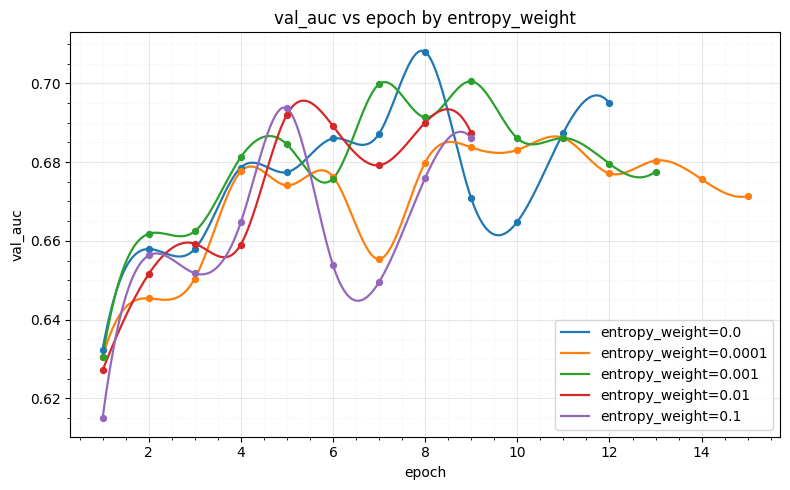


[EXPERIMENT START] impl=adaptive_gating | n_settings=5 | exp_tag=20261020-020650/seed_47

[SETTING 1/5] tag=ent0e+00 | xai=False | settings=entropy_weight=0
[RUN START] impl=adaptive_gating | tag=ent0e+00 | run_id=20261020-020650/seed_47__ent0e+00__e20 | xai=False | epochs=20 | seed=47
--------------------------------------------------------------------------------------------------------------
Epoch 1/20
38/38 - 109s - 3s/step - auc: 0.5112 - loss: 0.6256 - val_auc: 0.5587 - val_loss: 0.6091 - learning_rate: 2.5000e-05
Epoch 2/20
38/38 - 9s - 235ms/step - auc: 0.6930 - loss: 0.5657 - val_auc: 0.6580 - val_loss: 0.5913 - learning_rate: 1.2333e-04
Epoch 3/20
38/38 - 7s - 193ms/step - auc: 0.7179 - loss: 0.5503 - val_auc: 0.6538 - val_loss: 0.6089 - learning_rate: 2.2167e-04
Epoch 4/20
38/38 - 7s - 193ms/step - auc: 0.7558 - loss: 0.5258 - val_auc: 0.6483 - val_loss: 0.6349 - learning_rate: 3.2000e-04
Epoch 5/20
38/38 - 9s - 236ms/step - auc: 0.8134 - loss: 0.4819 - val_auc: 0.6870 - va

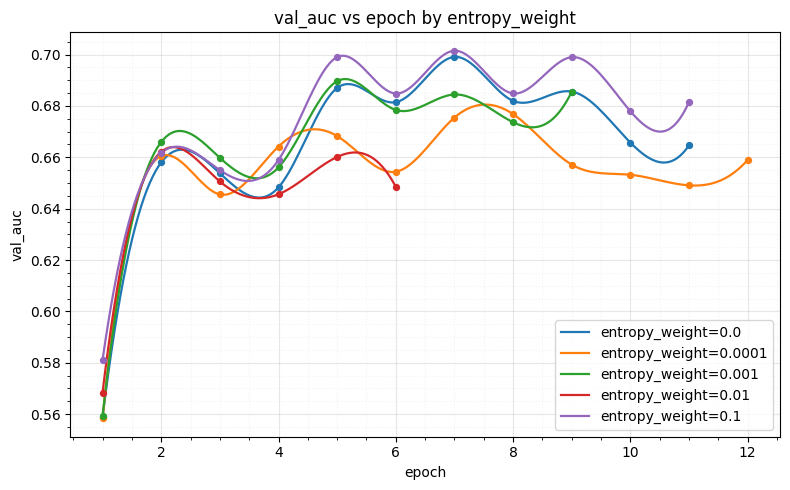


[EXPERIMENT START] impl=adaptive_gating | n_settings=5 | exp_tag=20261020-020650/seed_53

[SETTING 1/5] tag=ent0e+00 | xai=False | settings=entropy_weight=0
[RUN START] impl=adaptive_gating | tag=ent0e+00 | run_id=20261020-020650/seed_53__ent0e+00__e20 | xai=False | epochs=20 | seed=53
--------------------------------------------------------------------------------------------------------------
Epoch 1/20
38/38 - 112s - 3s/step - auc: 0.5403 - loss: 0.6355 - val_auc: 0.6324 - val_loss: 0.5959 - learning_rate: 2.5000e-05
Epoch 2/20
38/38 - 9s - 235ms/step - auc: 0.7083 - loss: 0.5589 - val_auc: 0.6692 - val_loss: 0.5916 - learning_rate: 1.2333e-04
Epoch 3/20
38/38 - 9s - 237ms/step - auc: 0.7263 - loss: 0.5466 - val_auc: 0.6746 - val_loss: 0.5814 - learning_rate: 2.2167e-04
Epoch 4/20
38/38 - 7s - 194ms/step - auc: 0.7697 - loss: 0.5176 - val_auc: 0.6634 - val_loss: 0.5960 - learning_rate: 3.2000e-04
Epoch 5/20
38/38 - 9s - 238ms/step - auc: 0.8096 - loss: 0.4828 - val_auc: 0.7041 - va

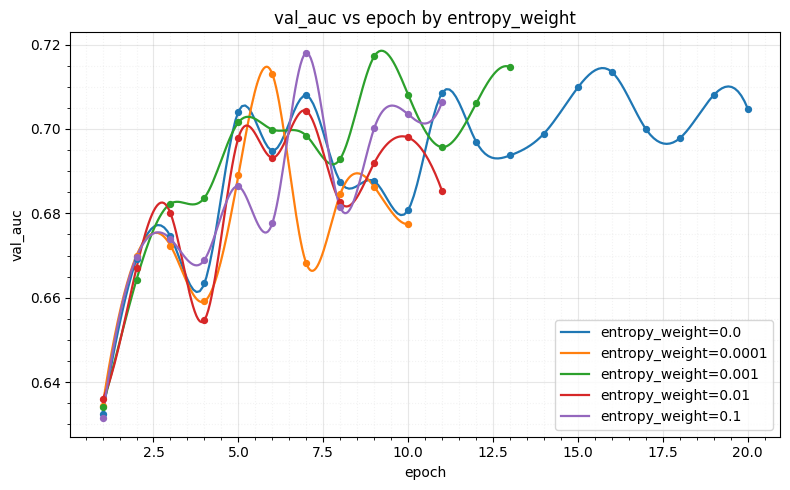


[EXPERIMENT START] impl=adaptive_gating | n_settings=5 | exp_tag=20261020-020650/seed_71

[SETTING 1/5] tag=ent0e+00 | xai=False | settings=entropy_weight=0
[RUN START] impl=adaptive_gating | tag=ent0e+00 | run_id=20261020-020650/seed_71__ent0e+00__e20 | xai=False | epochs=20 | seed=71
--------------------------------------------------------------------------------------------------------------
Epoch 1/20
38/38 - 112s - 3s/step - auc: 0.6136 - loss: 0.6024 - val_auc: 0.6358 - val_loss: 0.5919 - learning_rate: 2.5000e-05
Epoch 2/20
38/38 - 9s - 239ms/step - auc: 0.6915 - loss: 0.5667 - val_auc: 0.6504 - val_loss: 0.5898 - learning_rate: 1.2333e-04
Epoch 3/20
38/38 - 7s - 194ms/step - auc: 0.7316 - loss: 0.5435 - val_auc: 0.6493 - val_loss: 0.6556 - learning_rate: 2.2167e-04
Epoch 4/20
38/38 - 9s - 237ms/step - auc: 0.7593 - loss: 0.5249 - val_auc: 0.6516 - val_loss: 0.6393 - learning_rate: 3.2000e-04
Epoch 5/20
38/38 - 7s - 196ms/step - auc: 0.8124 - loss: 0.4806 - val_auc: 0.6474 - va

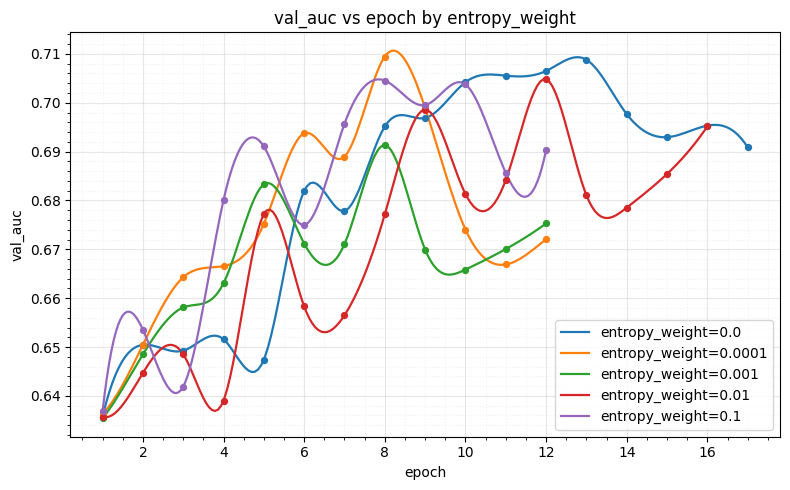


[EXPERIMENT START] impl=adaptive_gating | n_settings=5 | exp_tag=20261020-020650/seed_90

[SETTING 1/5] tag=ent0e+00 | xai=False | settings=entropy_weight=0
[RUN START] impl=adaptive_gating | tag=ent0e+00 | run_id=20261020-020650/seed_90__ent0e+00__e20 | xai=False | epochs=20 | seed=90
--------------------------------------------------------------------------------------------------------------
Epoch 1/20
38/38 - 112s - 3s/step - auc: 0.6208 - loss: 0.6041 - val_auc: 0.6215 - val_loss: 0.5938 - learning_rate: 2.5000e-05
Epoch 2/20
38/38 - 9s - 236ms/step - auc: 0.7080 - loss: 0.5586 - val_auc: 0.6425 - val_loss: 0.6071 - learning_rate: 1.2333e-04
Epoch 3/20
38/38 - 9s - 236ms/step - auc: 0.7442 - loss: 0.5356 - val_auc: 0.6592 - val_loss: 0.6211 - learning_rate: 2.2167e-04
Epoch 4/20
38/38 - 7s - 195ms/step - auc: 0.7832 - loss: 0.5087 - val_auc: 0.6591 - val_loss: 0.6221 - learning_rate: 3.2000e-04
Epoch 5/20
38/38 - 9s - 238ms/step - auc: 0.8341 - loss: 0.4609 - val_auc: 0.6683 - va

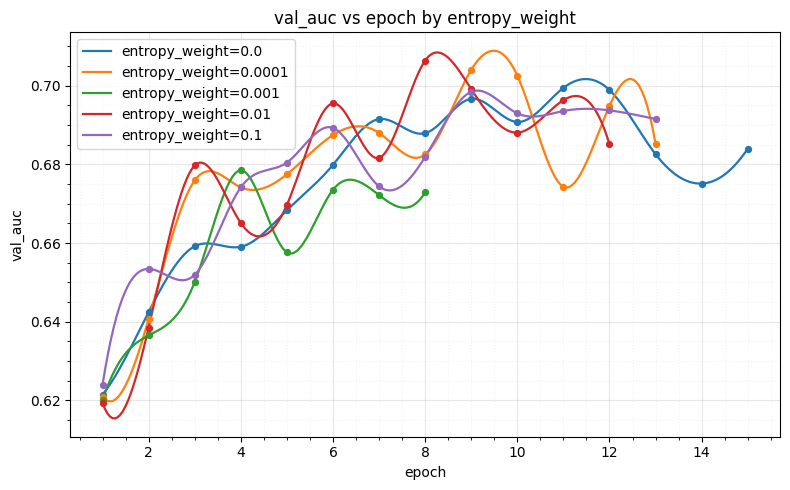


[EXPERIMENT START] impl=adaptive_gating | n_settings=5 | exp_tag=20261020-020650/seed_101

[SETTING 1/5] tag=ent0e+00 | xai=False | settings=entropy_weight=0
[RUN START] impl=adaptive_gating | tag=ent0e+00 | run_id=20261020-020650/seed_101__ent0e+00__e20 | xai=False | epochs=20 | seed=101
--------------------------------------------------------------------------------------------------------------
Epoch 1/20
38/38 - 112s - 3s/step - auc: 0.4663 - loss: 0.6609 - val_auc: 0.5299 - val_loss: 0.6099 - learning_rate: 2.5000e-05
Epoch 2/20
38/38 - 9s - 237ms/step - auc: 0.6864 - loss: 0.5731 - val_auc: 0.6575 - val_loss: 0.5851 - learning_rate: 1.2333e-04
Epoch 3/20
38/38 - 9s - 249ms/step - auc: 0.7261 - loss: 0.5461 - val_auc: 0.6589 - val_loss: 0.5951 - learning_rate: 2.2167e-04
Epoch 4/20
38/38 - 7s - 195ms/step - auc: 0.7713 - loss: 0.5176 - val_auc: 0.6485 - val_loss: 0.6546 - learning_rate: 3.2000e-04
Epoch 5/20
38/38 - 7s - 196ms/step - auc: 0.8001 - loss: 0.4947 - val_auc: 0.6570 -

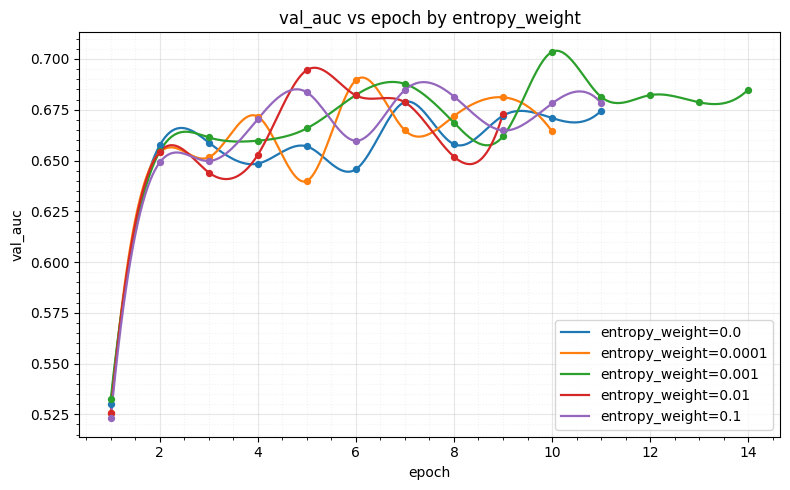

,impl_name,run_id,setting_tag,seed,best_val_auc,best_epoch,train_seconds,xai_done
0,adaptive_gating,20261020-020650/seed_8__ent0e+00__e20,ent0e+00,8,0.707995,7,224.227565,False
1,adaptive_gating,20261020-020650/seed_8__base__e20,base,8,0.686113,10,229.206266,False
2,adaptive_gating,20261020-020650/seed_8__ent1e-03__e20,ent1e-03,8,0.700494,8,211.435262,False
3,adaptive_gating,20261020-020650/seed_8__ent1e-02__e20,ent1e-02,8,0.692018,4,175.668440,False
4,adaptive_gating,20261020-020650/seed_8__ent1e-01__e20,ent1e-01,8,0.693621,4,177.020725,False
5,adaptive_gating,20261020-020650/seed_47__ent0e+00__e20,ent0e+00,47,0.699107,6,188.323599,False
6,adaptive_gating,20261020-020650/seed_47__base__e20,base,47,0.676813,7,203.325555,False
7,adaptive_gating,20261020-020650/seed_47__ent1e-03__e20,ent1e-03,47,0.689658,4,173.632293,False
8,adaptive_gating,20261020-020650/seed_47__ent1e-02__e20,ent1e-02,47,0.662162,1,151.219565,False
9,adaptive_gating,20261020-020650/seed_47__ent1e-01__e20,ent1e-01,47,0.701508,6,192.956927,False


,entropy_weight,mean,std,count,brier_mean,brier_std,ece_mean,ece_std,img_drop_mean,tab_drop_mean,balance_mean
0,0.0000,0.701276,0.012365,6,0.248089,0.018645,0.214158,0.025421,0.055719,0.024364,0.312626
1,0.0001,0.696503,0.014433,6,0.229699,0.018538,0.176187,0.030555,0.053650,0.020807,0.280586
2,0.0010,0.696785,0.013355,6,0.227896,0.024963,0.167311,0.053492,0.050213,0.030667,0.380368
3,0.0100,0.694034,0.016695,6,0.219912,0.017169,0.146283,0.050168,0.047547,0.030771,0.391872
4,0.1000,0.700145,0.011169,6,0.221565,0.011801,0.151088,0.027488,0.050063,0.030507,0.380742


AUC: 0.6977 ± 0.0130
[study dir]: /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/runs/adaptive_gating/20261020-020650


: 

In [ ]:
# @@SWEEP_GATING@@ — Adaptive gating entropy sweep over the existing six seeds
EPOCHS = CFG.epochs
SEEDS = CFG.seeds
ADAPTIVE_GATING_SETTINGS = [
    {"tag": "ent0e+00", "entropy_weight": 0.0},
    {"tag": "base", "entropy_weight": 1e-4},
    {"tag": "ent1e-03", "entropy_weight": 1e-3},
    {"tag": "ent1e-02", "entropy_weight": 1e-2},
    {"tag": "ent1e-01", "entropy_weight": 1e-1},
]
IMPL = "adaptive_gating"
STUDY_TAG = "20261020-020650"
study_tag, study_dir = open_study(IMPL, STUDY_TAG)


ag_all_results = []
ag_all_histories = {}

for seed in SEEDS:
    seed_exp_tag = os.path.join(study_tag, f"seed_{seed}")
    ag_seed_results, ag_seed_histories, ag_summary_dir = run_model_experiment(
        impl_name=IMPL,
        settings=ADAPTIVE_GATING_SETTINGS,
        build_model_from_setting_fn=lambda s, run_eagerly: fam.build_adaptive_gating(
            s, SPEC, run_eagerly
        ),
        enable_xai_fn=lambda s: True,
        epochs=EPOCHS,
        extra_meta_fn=lambda s: {"entropy_weight": float(s["entropy_weight"])},
        seed=seed,
        exp_tag=seed_exp_tag,
    )
    ag_all_results.append(ag_seed_results)
    ag_all_histories.update({f"{seed}__{k}": v for k, v in ag_seed_histories.items()})

    # per-seed plots stay inside the seed folder
    seed_plots_dir = os.path.join(ag_summary_dir, "plots")
    plot_val_auc_vs_epoch_sweep(
        ag_seed_results, ag_seed_histories, setting_col="entropy_weight",
        out_dir=seed_plots_dir, fname="val_auc_vs_epoch_adaptive_gating.png",
    )

# Cross-seed aggregation
ag_combined = pd.concat(ag_all_results, ignore_index=True)
ag_combined.to_csv(os.path.join(study_dir, "combined_summary.csv"), index=False)

ag_agg = ag_combined.groupby("entropy_weight").agg(
    mean=("best_val_auc", "mean"), std=("best_val_auc", "std"),
    count=("best_val_auc", "count"),
    brier_mean=("brier", "mean"), brier_std=("brier", "std"),
    ece_mean=("ece", "mean"), ece_std=("ece", "std"),
    img_drop_mean=("img_drop_auc", "mean"), tab_drop_mean=("tab_drop_auc", "mean"),
    balance_mean=("modality_balance", "mean"),
).reset_index()
ag_agg.to_csv(os.path.join(study_dir, "entropy_weight_aggregated.csv"), index=False)
display(ag_combined[["impl_name", "run_id", "setting_tag", "seed", "best_val_auc", "best_epoch", "train_seconds", "xai_done"]])
display(ag_agg)
print(f"AUC: {ag_combined['best_val_auc'].mean():.4f} ± {ag_combined['best_val_auc'].std():.4f}")
print("[study dir]:", study_dir)


In [ ]:
# @@ADAPTIVE GATING GATE_DIAGNOSTICS@@ — gate weights and entropy per run
for _, row in ag_combined.iterrows():
    ag_run_dir = row["run_dir"]
    with open(os.path.join(ag_run_dir, "history.json")) as f:
        ag_hist = json.load(f)

    plots_dir = os.path.join(ag_run_dir, "plots")
    os.makedirs(plots_dir, exist_ok=True)

    if "val_auc" in ag_hist and len(ag_hist["val_auc"]) > 0:
        x = np.arange(1, len(ag_hist["val_auc"]) + 1)
        plt.figure(figsize=(7, 4))
        plt.plot(x, ag_hist["val_auc"], marker="o")
        plt.xlabel("epoch"); plt.ylabel("val_auc")
        plt.title("Adaptive gating: val_auc vs epoch")
        plt.grid(alpha=0.3)
        _finalize_plot(plots_dir, "val_auc_vs_epoch.png")

    if "loss" in ag_hist and "val_loss" in ag_hist and len(ag_hist["loss"]) > 0:
        x = np.arange(1, len(ag_hist["loss"]) + 1)
        plt.figure(figsize=(7, 4))
        plt.plot(x, ag_hist["loss"], marker="o", label="loss")
        plt.plot(x, ag_hist["val_loss"], marker="o", label="val_loss")
        plt.xlabel("epoch"); plt.ylabel("loss")
        plt.title("Adaptive gating: loss vs epoch")
        plt.grid(alpha=0.3)
        plt.legend()
        _finalize_plot(plots_dir, "loss_vs_epoch.png")

In [ ]:
# @@SMOKE@@ — build every family on one real batch and check that nothing moved
# Parameter counts are recorded per configuration the first time and compared on every later run

SMOKE_SETTINGS = {                    
    "vanilla":             {},
    "fixed_scaling":       {"alpha": 0.5},
    "learnable_scaling":   {"init_alpha": 0.5},
    "loss_regularization": {"lambda_reg": 1e-4},
    "controlled_fusion":   {"gamma_img": 1.0, "gamma_tab": 1.0},
    "adaptive_gating":     {"entropy_weight": 1e-4},
}
SMOKE_XLA = False                      
FINGERPRINT = os.path.join(ART_PATH, "model_fingerprint.json")
CONFIG_KEY = f"{SPEC.preset}|{tuple(SPEC.image_size)}|{SPEC.encoded_dim}"

assert set(SMOKE_SETTINGS) == set(fam.FAMILIES), (
    f"every family needs a smoke setting: {set(fam.FAMILIES) ^ set(SMOKE_SETTINGS)}")

recorded = json.load(open(FINGERPRINT)) if os.path.exists(FINGERPRINT) else {}
reference = recorded.get(CONFIG_KEY, {})
batch_x, batch_y = next(iter(make_training_dataset(CFG.seeds[0])))

print("[provenance]", " | ".join(f"{k}={v}" for k, v in run_provenance().items()))
print(f"[smoke] {CONFIG_KEY} | batch {tuple(batch_x["images"].shape)}"
      f" | {"comparing with" if reference else "recording into"} {os.path.basename(FINGERPRINT)}")

for family, setting in SMOKE_SETTINGS.items():
    keras.backend.clear_session(); gc.collect()
    model = fam.FAMILIES[family](setting, SPEC, run_eagerly=True)
    n_params = model.count_params()
    batch_loss = model.test_on_batch(batch_x, batch_y, return_dict=True)["loss"]

    assert int(model.input["features"].shape[-1]) == SPEC.encoded_dim, f"{family}: wrong width"
    assert np.isfinite(batch_loss), f"{family}: non-finite loss"
    assert reference.get(family, n_params) == n_params, (
        f"{family}: {n_params:,} parameters against the {reference.get(family):,} recorded "
        f"for {CONFIG_KEY} — the architecture changed")
    if SMOKE_XLA:
        fam.FAMILIES[family](setting, SPEC, run_eagerly=False).train_on_batch(batch_x, batch_y)

    recorded.setdefault(CONFIG_KEY, {})[family] = n_params
    print(f"  {family:20s} loss {batch_loss:.4f}  params {n_params:,}  PASS")
    del model
json.dump(recorded, open(FINGERPRINT, "w"), indent=1)
keras.backend.clear_session(); gc.collect()
print(f"Smoke PASS — {len(SMOKE_SETTINGS)} families against {SPEC.encoded_dim} encoded features")
